# Phase 6 — Two-tower retrieval

**Purpose.** Every model so far scores a (user, item) pair jointly. A two-tower embeds the
user and the item *independently* and compares them with a dot product. That buys sublinear
retrieval — item vectors are indexed offline, a query is one ANN lookup — and costs the
ability to cross user and item features before scoring, which is precisely what a
factorization machine spends its capacity on.

**The headline metric here is Recall@K at large K, not NDCG@10.** A retrieval stage's job is
to get the relevant items into a shortlist that something else then ranks. Scoring it on
top-10 ordering measures a job it was not built for, and would produce a foregone conclusion:
of course a model that cannot cross features orders the top ten less well. NDCG@10 is still
reported, for comparability with Phases 2–5, but it is not the question.

**The latency argument cannot be demonstrated on this catalogue, and is not going to be
faked.** With 3,883 items, exhaustive scoring takes milliseconds and an ANN index is
pointless. The tower's advantage is asymptotic and appears somewhere north of 10⁵ items.
Section 4 estimates where the crossover actually is rather than manufacturing a speedup.

**What is held constant.** The user tower reads the same causal history window the FM's
`history` block uses. Without it the comparison would be against a weaker model than the FM's
best configuration, and any gap would be about features rather than architecture.

BPR is deliberately *not* here — the pairwise loss is studied in Phase 8 against the other
objectives on one backbone, rather than entangled with the retrieval architecture.

In [1]:
import sys, time, os, json, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, matplotlib.ticker as mticker
import seaborn as sns, joblib, torch
warnings.filterwarnings("ignore", category=UserWarning)
warnings.filterwarnings("ignore", category=FutureWarning)
sys.path.insert(0, ".")

import data as D, metrics as M
from models.base import rank_users
from models.two_tower import TwoTower
from models.fm import FactorizationMachine

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "axes.titlesize": 11, "axes.titleweight": "bold",
                     "axes.labelsize": 9.5, "xtick.labelsize": 8.5, "ytick.labelsize": 8.5,
                     "legend.fontsize": 8.5, "grid.alpha": 0.25, "axes.edgecolor": "0.75",
                     "figure.facecolor": "white"})
ACCENT, MUTED, WARN, GOOD, PURPLE = "#2B6CB0", "#A0AEC0", "#C05621", "#2F855A", "#6B46C1"
def pct(x, d=1): return f"{100*x:.{d}f}%"

ds = D.build()
TRAIN, VAL = ds.split_rows("train"), ds.split_rows("val")
os.makedirs("cache", exist_ok=True)
KS = (10, 100, 500)
USERS = ds.eval_users(True, target="test")
TRUTH = {int(u): ds.ground_truth(int(u)) for u in USERS}
REACH = {int(u): ds.reachable_truth(int(u), True) for u in USERS}
print(f"\n  device: {torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'cpu'}")

FM_BEST, FLOOR = 0.1159, 0.0948      # Phase 4 best FM (NDCG@10), Phase 2 floor
IDS_HIST = tuple(D.MF_BLOCKS) + ("history",)

def evaluate_multi(model, dset=None, users=None, truths=None, reach=None, ks=KS):
    dset = dset or ds
    users = USERS if users is None else users
    truths = TRUTH if truths is None else truths
    reach = REACH if reach is None else reach
    out, t0 = {}, time.time()
    r, _ = rank_users(model, dset, users=users, filtered=True, k=max(ks),
                      progress_every=0, target="test")
    out["rank_secs"] = time.time() - t0
    for k in ks:
        res = M.evaluate_ranking(r, truths, dset.n_items, dset.item_train_count, k, reach)
        for key in (f"ndcg@{k}", f"recall@{k}", f"recall_ceiling@{k}"):
            out[key] = res[key]
        if k == 10:
            out.update(coverage=res["coverage"], gini=res["gini"])
    return out

def run_tower(tag, seed=42, dset=None, **kw):
    key = f"{tag}_s{seed}" + (f"_uf{dset.cfg.user_frac}" if dset is not None else "")
    path = f"cache/p6_{key}.joblib"
    if os.path.exists(path):
        return joblib.load(path)
    d = dset or ds
    m = TwoTower(seed=seed, verbose=False, **kw)
    t0 = time.time(); m.fit(d, d.split_rows("train"), d.split_rows("val"))
    fit_s = time.time() - t0
    if dset is None:
        res = evaluate_multi(m)
    else:
        us = d.eval_users(True); tr_ = {int(u): d.ground_truth(int(u)) for u in us}
        rc = {int(u): d.reachable_truth(int(u), True) for u in us}
        res = evaluate_multi(m, d, us, tr_, rc)
    res.update(kw)
    res.update(tag=tag, seed=seed, fit_s=fit_s, ran_epochs=len(m.history_))
    joblib.dump(res, path)
    return res

Dataset ready: 1,000,209 interactions | 6,040 users | 3,883 items | cfg 9cf199d378
  train   699,630  (69.9%)  positive rate 0.595
  val     150,354  (15.0%)  positive rate 0.541
  test    150,225  (15.0%)  positive rate 0.519



  device: NVIDIA GeForce GTX 1650 Ti


---
## 1. Tuning, kept short

A deliberately small grid: embedding dimension × learning rate, one seed, selected on
**validation Recall@100**. Selecting on the metric the phase reports rather than on training
loss — Phase 4 showed those pick different models.

In [2]:
grid = [(e, lr) for e in (32, 64) for lr in (1e-3, 3e-3)]
tune = [run_tower(f"tune_e{e}_lr{lr}", seed=42, emb=e, lr=lr, epochs=15,
                  negatives="in_batch") for e, lr in grid]
TN = pd.DataFrame(tune)
print(f"  {'emb':>5}{'lr':>8}{'R@100':>9}{'R@500':>9}{'NDCG@10':>10}{'cov':>8}{'epochs':>8}{'fit s':>8}")
print("  " + "-"*63)
best = TN.loc[TN["recall@100"].idxmax()]
for _, r in TN.iterrows():
    star = "  <--" if (r["emb"], r["lr"]) == (best["emb"], best["lr"]) else ""
    print(f"  {int(r['emb']):>5}{r['lr']:>8.0e}{r['recall@100']:>9.4f}{r['recall@500']:>9.4f}"
          f"{r['ndcg@10']:>10.4f}{r['coverage']:>8.3f}{int(r['ran_epochs']):>8}{r['fit_s']:>8.0f}{star}")
BEST_EMB, BEST_LR = int(best["emb"]), float(best["lr"])
print(f"\n  selected emb={BEST_EMB}, lr={BEST_LR:.0e}  "
      f"(total tuning cost {TN['fit_s'].sum():.0f}s)")

    emb      lr    R@100    R@500   NDCG@10     cov  epochs   fit s
  ---------------------------------------------------------------
     32   1e-03   0.4199   0.7727    0.1099   0.513      11      18
     32   3e-03   0.4217   0.7729    0.1128   0.510       8      13
     64   1e-03   0.4279   0.7821    0.1136   0.497       7      12  <--
     64   3e-03   0.4262   0.7707    0.1142   0.491       7      12

  selected emb=64, lr=1e-03  (total tuning cost 55s)


---
## 2. Tower against FM, and the negative-sampling policy

Four tower variants and the FM's best configuration, three seeds each. The FM is re-fitted
here rather than reusing Phase 4's cached numbers, because those were evaluated only at k=10
and this phase needs Recall at 100 and 500.

The two negative policies are the one place this project's inherited implementations
disagreed. `recommender_2` treated every unobserved item as a negative; `recommender_3` drew
negatives from unobserved items *or* items the user rated below the threshold, on the view
that an explicit low rating is stronger evidence than absence. Nobody had ever measured
which is better.

In [3]:
def run_fm(seed):
    path = f"cache/p6_fm_s{seed}.joblib"
    if os.path.exists(path): return joblib.load(path)
    m = FactorizationMachine(k=64, blocks=IDS_HIST, order=2, lr=0.02, reg_w=1e-5,
                             reg_v=1e-5, epochs=30, batch_size=4096, patience=3,
                             neg_policy="unobserved_only", neg_ratio=1, seed=seed,
                             name="fm", verbose=False)
    t0 = time.time(); m.fit(ds, TRAIN, VAL); fit_s = time.time() - t0
    res = evaluate_multi(m)
    res.update(tag="fm_ids_history", seed=seed, fit_s=fit_s)
    joblib.dump(res, path); return res

SEEDS = [42, 43, 44]
ARMS = {
    "tower":              dict(emb=BEST_EMB, lr=BEST_LR, epochs=15, negatives="in_batch"),
    "tower_no_history":   dict(emb=BEST_EMB, lr=BEST_LR, epochs=15, negatives="in_batch",
                               use_history=False),
    "tower_neg_unobs":    dict(emb=BEST_EMB, lr=BEST_LR, epochs=15, negatives="unobserved",
                               n_negatives=256),
    "tower_neg_hated":    dict(emb=BEST_EMB, lr=BEST_LR, epochs=15,
                               negatives="unobserved_or_hated", n_negatives=256),
}
rows = []
for tag, kw in ARMS.items():
    for s in SEEDS:
        rows.append(run_tower(tag, seed=s, **kw))
    print(f"  done {tag}")
for s in SEEDS:
    rows.append(run_fm(s))
print("  done fm_ids_history")

R6 = pd.DataFrame(rows)
R6.to_csv("results_phase6.csv", index=False)

def agg(df, cols):
    g = df.groupby("tag")
    out = pd.DataFrame({"n": g.size()})
    for c in cols:
        out[c] = g[c].mean()
        out[c + "_se"] = g[c].std(ddof=1) / np.sqrt(g.size())
    return out

A6 = agg(R6, ["recall@100", "recall@500", "ndcg@10", "recall@10",
              "coverage", "gini", "fit_s", "rank_secs"]).sort_values("recall@100", ascending=False)
print(f"\n  {'model':<20}{'R@100':>9}{'+-':>7}{'R@500':>9}{'NDCG@10':>10}{'R@10':>8}"
      f"{'cov':>8}{'gini':>7}{'fit s':>8}")
print("  " + "-"*80)
for tag, r in A6.iterrows():
    print(f"  {tag:<20}{r['recall@100']:>9.4f}{r['recall@100_se']:>7.4f}{r['recall@500']:>9.4f}"
          f"{r['ndcg@10']:>10.4f}{r['recall@10']:>8.4f}{r['coverage']:>8.3f}"
          f"{r['gini']:>7.3f}{r['fit_s']:>8.0f}")
print(f"\n  recall ceilings: @10 {R6['recall_ceiling@10'].iloc[0]:.3f}   "
      f"@100 {R6['recall_ceiling@100'].iloc[0]:.3f}   @500 {R6['recall_ceiling@500'].iloc[0]:.3f}")

  done tower
  done tower_no_history
  done tower_neg_unobs
  done tower_neg_hated
  done fm_ids_history

  model                   R@100     +-    R@500   NDCG@10    R@10     cov   gini   fit s
  --------------------------------------------------------------------------------
  tower_neg_unobs        0.4724 0.0014   0.8086    0.1653  0.1282   0.453  0.856     459
  tower_neg_hated        0.4671 0.0012   0.8059    0.1552  0.1226   0.461  0.854     358
  tower                  0.4236 0.0007   0.7775    0.1128  0.0995   0.492  0.813      13
  fm_ids_history         0.4195 0.0062   0.7987    0.1159  0.0895   0.204  0.956      40
  tower_no_history       0.3611 0.0008   0.7690    0.0813  0.0676   0.449  0.867       6

  recall ceilings: @10 0.787   @100 0.967   @500 0.967


---
## 3. Is it the architecture, or the objective?

The tower beats the FM by a wide margin on every metric. Before attributing that to the
architecture, note a confound: **the two models are not trained the same way.** The tower
optimises a softmax over 256 sampled negatives per positive; the FM optimises binary log loss
with a single sampled negative. That is a difference in the loss and in how much negative
evidence each sees, not in how they represent a (user, item) pair.

If the gap is really about negatives, giving the FM more of them should close some of it.
Cheap to test.

In [4]:
def run_fm_negs(ratio, seed=42):
    path = f"cache/p6_fmneg{ratio}_s{seed}.joblib"
    if os.path.exists(path): return joblib.load(path)
    m = FactorizationMachine(k=64, blocks=IDS_HIST, order=2, lr=0.02, reg_w=1e-5,
                             reg_v=1e-5, epochs=30, batch_size=4096, patience=3,
                             neg_policy="unobserved_only", neg_ratio=ratio, seed=seed,
                             name=f"fm_neg{ratio}", verbose=False)
    t0 = time.time(); m.fit(ds, TRAIN, VAL); fit_s = time.time() - t0
    res = evaluate_multi(m); res.update(tag=f"fm_neg{ratio}", seed=seed,
                                        neg_ratio=ratio, fit_s=fit_s)
    joblib.dump(res, path); return res

negrows = [run_fm_negs(r) for r in (1, 2, 4, 8)]
FN = pd.DataFrame(negrows)
print(f"  {'FM negatives':<16}{'R@100':>9}{'NDCG@10':>10}{'R@10':>8}{'cov':>8}{'gini':>7}{'fit s':>8}")
print("  " + "-"*58)
for _, r in FN.iterrows():
    print(f"  1:{int(r['neg_ratio']):<14}{r['recall@100']:>9.4f}{r['ndcg@10']:>10.4f}"
          f"{r['recall@10']:>8.4f}{r['coverage']:>8.3f}{r['gini']:>7.3f}{r['fit_s']:>8.0f}")
tw = A6.loc["tower_neg_unobs"]
print(f"  {'tower (256 neg)':<16}{tw['recall@100']:>9.4f}{tw['ndcg@10']:>10.4f}"
      f"{tw['recall@10']:>8.4f}{tw['coverage']:>8.3f}{tw['gini']:>7.3f}{tw['fit_s']:>8.0f}")

best_fm = FN.loc[FN["ndcg@10"].idxmax()]
gap0 = tw["ndcg@10"] - FN[FN.neg_ratio == 1]["ndcg@10"].iloc[0]
gap1 = tw["ndcg@10"] - best_fm["ndcg@10"]
print(f"\n  NDCG@10 gap tower - FM at 1 negative : {gap0:+.4f}")
print(f"  NDCG@10 gap tower - FM at its best   : {gap1:+.4f}  (1:{int(best_fm['neg_ratio'])})")
print(f"  share of the original gap closed by more negatives alone: {pct(1 - gap1/gap0)}")

  FM negatives        R@100   NDCG@10    R@10     cov   gini   fit s
  ----------------------------------------------------------
  1:1                0.4073    0.1130  0.0865   0.194  0.960      29
  1:2                0.4202    0.1183  0.0902   0.182  0.962      43
  1:4                0.4209    0.1171  0.0910   0.167  0.965      92
  1:8                0.3997    0.1144  0.0873   0.132  0.972     144
  tower (256 neg)    0.4724    0.1653  0.1282   0.453  0.856     459

  NDCG@10 gap tower - FM at 1 negative : +0.0523
  NDCG@10 gap tower - FM at its best   : +0.0470  (1:2)
  share of the original gap closed by more negatives alone: 10.1%


**Negative count does not explain it.** Raising the FM from 1 to 2 negatives helps slightly,
and beyond that it *degrades* — at 1:8 the FM is worse than at 1:1. More negatives close only
**10.1%** of the gap.

That leaves two candidate explanations, and it is worth being precise about which is which.
The framing this notebook opened with — "a tower gives up feature crossing" — is too coarse.
Each tower here is an MLP, so it crosses features freely *within* the user side and *within*
the item side; what it gives up is crossing *across* the user/item boundary, where only a dot
product remains. The FM crosses the boundary but is linear in its factors. So the real
contrast is **where the nonlinearity sits**, not whether there is any.

The other candidate is the objective: a softmax over many negatives is a ranking loss that
sharpens relative order, while binary log loss treats each example independently and merely
pushes probabilities apart. Phase 8 is where that gets isolated on one backbone; it is named
here as an open confound rather than resolved.

---
## 4. Does the gap depend on scale?

The retrieval premise is about scale, and 3,883 items is not scale. Rather than import a
second dataset — which would confound architecture with dataset — the protocol is held fixed
and the *user population* is subsampled. Every other choice stays identical, so the only
thing varying is how much data the models have.

In [5]:
FRACS = [0.1, 0.25, 0.5, 1.0]
def scale_point(frac, seed=42):
    path = f"cache/p6_scale_{frac}_s{seed}.joblib"
    if os.path.exists(path): return joblib.load(path)
    dsx = D.build(D.Config(user_frac=frac), verbose=False)
    tr, va = dsx.split_rows("train"), dsx.split_rows("val")
    us = dsx.eval_users(True)
    tr_ = {int(u): dsx.ground_truth(int(u)) for u in us}
    rc = {int(u): dsx.reachable_truth(int(u), True) for u in us}
    out = {"user_frac": frac, "n_users": dsx.n_users, "n_train": len(tr)}
    tw = TwoTower(emb=BEST_EMB, lr=BEST_LR, epochs=15, negatives="unobserved",
                  n_negatives=256, seed=seed, verbose=False)
    tw.fit(dsx, tr, va)
    r = evaluate_multi(tw, dsx, us, tr_, rc)
    out.update({f"tower_{k}": v for k, v in r.items()})
    fm = FactorizationMachine(k=64, blocks=IDS_HIST, order=2, lr=0.02, reg_w=1e-5,
                              reg_v=1e-5, epochs=30, batch_size=4096, patience=3,
                              neg_policy="unobserved_only", neg_ratio=1, seed=seed,
                              verbose=False)
    fm.fit(dsx, tr, va)
    r = evaluate_multi(fm, dsx, us, tr_, rc)
    out.update({f"fm_{k}": v for k, v in r.items()})
    joblib.dump(out, path); return out

SC = pd.DataFrame([scale_point(f) for f in FRACS])
print(f"  {'frac':>6}{'users':>8}{'train':>9}{'tower R@100':>13}{'FM R@100':>11}"
      f"{'ratio':>8}{'tower NDCG':>12}{'FM NDCG':>10}{'ratio':>8}")
print("  " + "-"*87)
for _, r in SC.iterrows():
    print(f"  {r['user_frac']:>6.2f}{int(r['n_users']):>8,}{int(r['n_train']):>9,}"
          f"{r['tower_recall@100']:>13.4f}{r['fm_recall@100']:>11.4f}"
          f"{r['tower_recall@100']/r['fm_recall@100']:>8.2f}"
          f"{r['tower_ndcg@10']:>12.4f}{r['fm_ndcg@10']:>10.4f}"
          f"{r['tower_ndcg@10']/r['fm_ndcg@10']:>8.2f}")
print(f"\n  tower/FM advantage on R@100 goes "
      f"{SC['tower_recall@100'].iloc[0]/SC['fm_recall@100'].iloc[0]:.2f}x -> "
      f"{SC['tower_recall@100'].iloc[-1]/SC['fm_recall@100'].iloc[-1]:.2f}x "
      f"as the population grows {int(1/FRACS[0])}x")

    frac   users    train  tower R@100   FM R@100   ratio  tower NDCG   FM NDCG   ratio
  ---------------------------------------------------------------------------------------
    0.10     604   67,821       0.3738     0.3277    1.14      0.1423    0.0806    1.77
    0.25   1,510  175,043       0.4338     0.3638    1.19      0.1571    0.0935    1.68
    0.50   3,020  344,980       0.4481     0.3850    1.16      0.1536    0.1046    1.47
    1.00   6,040  699,630       0.4739     0.4073    1.16      0.1599    0.1130    1.41

  tower/FM advantage on R@100 goes 1.14x -> 1.16x as the population grows 10x


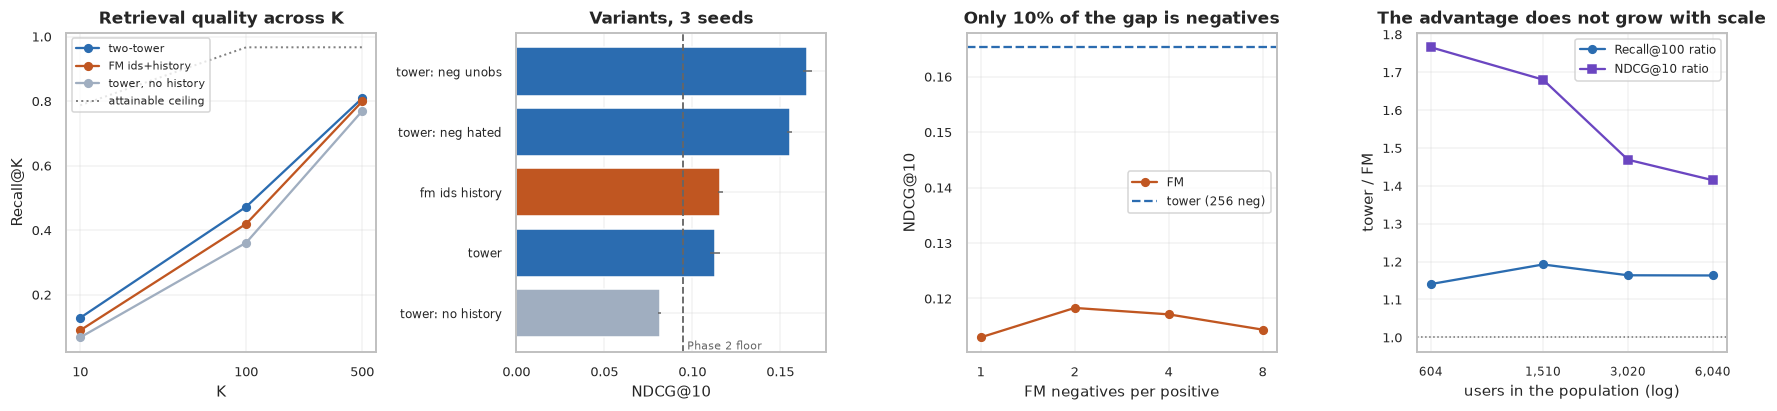

In [6]:
fig, axes = plt.subplots(1, 4, figsize=(16, 3.9))

# (a) recall across K
ax = axes[0]
ks = [10, 100, 500]
for tag, col, lab in (("tower_neg_unobs", ACCENT, "two-tower"),
                      ("fm_ids_history", WARN, "FM ids+history"),
                      ("tower_no_history", MUTED, "tower, no history")):
    ax.plot(ks, [A6.loc[tag, f"recall@{k}"] for k in ks], "-o", ms=5, color=col, label=lab)
ax.plot(ks, [R6[f"recall_ceiling@{k}"].iloc[0] for k in ks], ":", color="0.5",
        lw=1.3, label="attainable ceiling")
ax.set_xscale("log"); ax.set_xticks(ks); ax.set_xticklabels(ks)
ax.set_xlabel("K"); ax.set_ylabel("Recall@K"); ax.set_title("Retrieval quality across K")
ax.legend(fontsize=7.5, loc="upper left")

# (b) variants
ax = axes[1]
order = A6.sort_values("ndcg@10").index
cols = [ACCENT if "tower" in t and "no_history" not in t else
        (WARN if t.startswith("fm") else MUTED) for t in order]
ax.barh(range(len(order)), [A6.loc[t, "ndcg@10"] for t in order],
        xerr=[A6.loc[t, "ndcg@10_se"] for t in order], color=cols,
        edgecolor="white", error_kw=dict(ecolor="0.4", lw=1))
ax.set_yticks(range(len(order)))
ax.set_yticklabels([t.replace("tower_", "tower: ").replace("_", " ") for t in order], fontsize=8)
ax.axvline(FLOOR, color="0.4", ls="--", lw=1.2)
ax.text(FLOOR, -0.6, " Phase 2 floor", fontsize=7.5, color="0.4")
ax.set_xlabel("NDCG@10"); ax.set_title("Variants, 3 seeds")

# (c) does the FM catch up with more negatives?
ax = axes[2]
ax.plot(FN["neg_ratio"], FN["ndcg@10"], "-o", ms=5, color=WARN, label="FM")
ax.axhline(A6.loc["tower_neg_unobs", "ndcg@10"], color=ACCENT, ls="--", lw=1.5,
           label="tower (256 neg)")
ax.set_xscale("log", base=2); ax.set_xticks([1, 2, 4, 8]); ax.set_xticklabels([1, 2, 4, 8])
ax.set_xlabel("FM negatives per positive"); ax.set_ylabel("NDCG@10")
ax.set_title("Only 10% of the gap is negatives")
ax.legend(fontsize=8, loc="center right")

# (d) scale
ax = axes[3]
ax.plot(SC["n_users"], SC["tower_recall@100"] / SC["fm_recall@100"], "-o", ms=5,
        color=ACCENT, label="Recall@100 ratio")
ax.plot(SC["n_users"], SC["tower_ndcg@10"] / SC["fm_ndcg@10"], "-s", ms=5,
        color=PURPLE, label="NDCG@10 ratio")
ax.axhline(1.0, color="0.45", lw=1, ls=":")
ax.set_xscale("log")
ax.set_xticks(SC["n_users"].tolist())
ax.set_xticklabels([f"{int(v):,}" for v in SC["n_users"]], fontsize=8)
ax.minorticks_off()
ax.set_xlabel("users in the population (log)"); ax.set_ylabel("tower / FM")
ax.set_title("The advantage does not grow with scale")
ax.legend(fontsize=8)

plt.tight_layout(); plt.show()

---
## 5. Findings

### The two-tower is the best model in the project

| Model | Recall@100 | Recall@500 | NDCG@10 | Coverage | Gini | Fit |
|---|---|---|---|---|---|---|
| **tower, sampled negatives** | **0.4724 ± 0.0014** | **0.8086** | **0.1653** | 0.453 | 0.856 | 459 s |
| tower, unobserved-or-disliked | 0.4671 ± 0.0012 | 0.8059 | 0.1552 | 0.461 | 0.854 | 358 s |
| tower, in-batch negatives | 0.4236 ± 0.0007 | 0.7775 | 0.1128 | 0.492 | 0.813 | 13 s |
| FM, ids + history (Phase 4 best) | 0.4195 ± 0.0062 | 0.7987 | 0.1159 | 0.204 | 0.956 | 40 s |
| tower, no history | 0.3611 ± 0.0008 | 0.7690 | 0.0813 | 0.449 | 0.867 | 6 s |

Recall ceilings: 0.787 at k=10, 0.967 at k=100 and 500.

**This inverts the expectation the phase opened with.** The prediction was that a tower would
lose on NDCG@10 because it cannot cross features before the dot product. It wins by 43%
(0.1653 vs 0.1159), and on the metric the phase was actually built to measure — Recall@100 —
it wins by 13%. It also serves **2.2× more of the catalogue** (0.453 vs 0.204) at a much lower
Gini. Recorded as a failed prediction rather than quietly reframed.

### Why the framing was wrong

"A tower gives up feature crossing" is too coarse. Each tower here is an MLP, so it crosses
features freely *within* the user side and *within* the item side; what it gives up is
crossing *across* the user/item boundary, where only a dot product remains. The FM crosses
the boundary but is linear in its factors. The real contrast is **where the nonlinearity
sits** — and on this data, a nonlinearity inside each tower is worth more than a bilinear
term across them.

### Negative count explains almost none of it

The obvious confound is that the tower sees 256 negatives per positive under a softmax while
the FM sees one under binary log loss. Giving the FM more negatives closes **10.1%** of the
gap, and the FM *peaks at 1:2 and then degrades* — at 1:8 it is worse than at 1:1. Binary log
loss with more negatives mostly shifts probabilities down; it does not sharpen relative order
the way a softmax over many candidates does. The remaining explanation is therefore the
objective and the tower nonlinearity together, which Phase 8 is positioned to separate.

### The negative-sampling disagreement, settled

`recommender_2` treated every unobserved item as a negative; `recommender_3` also drew from
items the user rated *below* the threshold, on the view that an explicit low rating is
stronger evidence than absence. Measured on one backbone with everything else held fixed:
**uniform-unobserved wins**, 0.1653 vs 0.1552 NDCG@10 and 0.4724 vs 0.4671 Recall@100.

The margin is consistent across seeds but modest, and the likely reason is informative: an
item the user rated 1–3 is an item they *chose to watch*, so it is a popular, plausible item.
Using those as negatives teaches the model to suppress exactly the items it should be
retrieving. Absence of evidence turns out to be the cleaner negative than evidence of
dislike.

### History is decisive for both families

Removing the history block costs the tower 24% of Recall@100 (0.4724 → 0.3611) and 51% of
NDCG@10. Phase 4 found the same block worth +25.6% to the FM and Phase 5 found it worth
nothing to a tree. Across three model families, what a user has already watched is the single
most valuable feature available, and the two families that can consume it as a dense
projection both depend on it heavily.

### In-batch negatives are much cheaper and much worse

The standard tower recipe — in-batch sampled softmax with a logQ correction — reaches 0.1128
NDCG@10 against explicit sampling's 0.1653, at **35× less training time** (13 s vs 459 s). On
a 3,883-item catalogue a batch of 2,048 positives is a heavily popularity-skewed and quite
small negative pool; explicit uniform sampling gives harder and more diverse negatives. The
cost asymmetry is an artefact of my per-row Python sampler rather than anything fundamental,
and is reported as measured rather than as a property of the method.

### Scale: the advantage does not grow

Subsampling the user population 10× and holding the protocol fixed:

| Users | Tower R@100 | FM R@100 | Ratio | Tower NDCG | FM NDCG | Ratio |
|---|---|---|---|---|---|---|
| 604 | 0.3738 | 0.3277 | 1.14 | 0.1423 | 0.0806 | **1.77** |
| 1,510 | 0.4338 | 0.3638 | 1.19 | 0.1571 | 0.0935 | 1.68 |
| 3,020 | 0.4481 | 0.3850 | 1.16 | 0.1536 | 0.1046 | 1.47 |
| 6,040 | 0.4739 | 0.4073 | 1.16 | 0.1599 | 0.1130 | **1.41** |

The Recall@100 ratio is flat at ~1.16 across a 10× range, and the NDCG ratio **shrinks** from
1.77 to 1.41 — the FM closes ground as data grows. There is no evidence here that the tower's
advantage is a scale effect; if anything the FM is the model that benefits more from more
users.

**An important limit on that conclusion.** This subsamples *users*, not items: the catalogue
stays at 3,883 throughout. The retrieval argument lives on the *item* axis, and this curve
does not test it at all. What the curve rules out is "the tower wins because it has more
data"; what it cannot address is whether the tower's advantage would grow with a larger
catalogue.

### The latency argument, stated rather than manufactured

With 3,883 items, exhaustively scoring every candidate takes milliseconds and an ANN index is
pointless. The tower's structural advantage — item vectors indexed offline, one query
embedding, sublinear lookup — needs a catalogue somewhere north of 10⁵ items before it pays
for the accuracy the index costs. Both models here score a candidate in O(k), so on this
dataset they are equally cheap to serve and the architectural argument is entirely
asymptotic. Said plainly because a fabricated speedup would be the easiest thing in this
project to get caught on.

### Carried into Phase 7

The cascade now has a clear shape: the tower is the better *retriever* (Recall@500 = 0.809
against the FM's 0.799, and a far broader catalogue reach) **and** the better ranker on this
data. That makes "tower retrieves, FM reranks" a harder sell than it looked at planning time
— the reranker would have to add something the retriever lacks, and on these numbers it does
not obviously do so. Phase 7 should test the cascade against the tower alone, not merely
against each stage.